# Linear regression – predicting order revenue

**Video 9.3** · ShopKart project

**Goal:** Train your first model: a linear regression that estimates how much revenue an order will bring, then measure its error in rupees (MAE, RMSE) and R².

**How to open in Colab:** go to colab.research.google.com → File → Upload notebook → choose this file. Then click the folder icon on the left and drag these data files in: `shopkart_clean.csv`. Then run cells from top to bottom (Shift + Enter).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("shopkart_clean.csv")

## An important choice: which features?
Revenue is calculated by a formula: `revenue = quantity × unit_price × (1 − discount)`.
If we give the model `unit_price`, `quantity` and `discount`, it is basically being handed the answer. That is not "learning", and in real life you would just use the formula.

So we ask a more useful business question: **before we know which exact product a customer will buy, how much revenue should we expect from an order?** We only use: category, quantity, discount, membership and city. No `unit_price`.

(At the end of this notebook we show what happens WITH `unit_price`, so you see the difference.)

## Step 1 – a one-feature model (the idea of a line)
Start simple: does quantity alone predict revenue? The model draws the best straight line: `revenue = intercept + slope × quantity`.

In [2]:
X1 = df[["quantity"]]
y = df["revenue"]
X1_train, X1_test, y_train, y_test = train_test_split(X1, y, test_size=0.2, random_state=42)

line = LinearRegression()
line.fit(X1_train, y_train)
print("Intercept:", round(line.intercept_, 0))
print("Slope    :", round(line.coef_[0], 0), "₹ extra per extra item")
print("R² on test:", round(line.score(X1_test, y_test), 3))

Intercept: -681.0
Slope    : 2035.0 ₹ extra per extra item
R² on test: 0.007


R² close to 0 means quantity alone explains almost nothing: 1 phone is worth far more than 3 books. The model needs to know **what kind** of product it is. Let's add more features.

## Step 2 – prepare X with more features

In [3]:
features = ["category", "quantity", "discount", "membership", "city"]
X = pd.get_dummies(df[features], drop_first=True, dtype=int)
y = df["revenue"]
print(X.shape)
X.head(3)

(5000, 16)


,quantity,discount,category_Books,category_Electronics,category_Fashion,category_Home,membership_Prime,city_Bengaluru,city_Chennai,city_Delhi,city_Hyderabad,city_Jaipur,city_Kolkata,city_Lucknow,city_Mumbai,city_Pune
0,6,0.20,1,0,0,0,1,0,0,1,0,0,0,0,0,0
1,2,0.05,0,0,0,0,0,0,1,0,0,0,0,0,0,0
2,1,0.05,0,0,1,0,1,0,0,1,0,0,0,0,0,0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_train), "train orders,", len(X_test), "test orders")

4000 train orders, 1000 test orders


## Step 3 – fit the model and predict

In [5]:
model = LinearRegression()
model.fit(X_train, y_train)          # learn from the training orders
pred = model.predict(X_test)         # estimate revenue for orders it has never seen

compare = pd.DataFrame({"actual ₹": y_test.values[:8], "predicted ₹": pred[:8].round(0)})
compare

,actual ₹,predicted ₹
0,430.00,-891.0
1,1366.00,3325.0
2,1295.80,5203.0
3,1482.95,5019.0
4,3634.70,3103.0
5,2227.75,973.0
6,1696.50,1038.0
7,815.10,4594.0


## Step 4 – what did the model learn? (coefficients)
Each coefficient = how many rupees that feature adds or removes, keeping the others the same. For category and city, it is compared with the dropped column (Beauty, Ahmedabad).

In [6]:
coefs = pd.Series(model.coef_, index=X.columns).round(0).sort_values(ascending=False)
print("Intercept:", round(model.intercept_, 0))
coefs

Intercept: -2704.0


category_Electronics    5920.0
quantity                2370.0
category_Home           2092.0
category_Fashion        1866.0
city_Bengaluru            50.0
city_Kolkata             -49.0
membership_Prime         -93.0
city_Hyderabad          -161.0
category_Books          -221.0
city_Chennai            -239.0
city_Pune               -252.0
city_Mumbai             -337.0
city_Delhi              -577.0
city_Lucknow            -678.0
city_Jaipur             -703.0
discount               -4448.0
dtype: float64

## Step 5 – evaluate in rupees
- **MAE** (mean absolute error): on average, how many ₹ is the guess off? Easy to explain to a manager.
- **RMSE** (root mean squared error): like MAE but punishes big misses more. Always ≥ MAE.
- **R²**: share of the ups and downs in revenue the model explains. 1 = perfect, 0 = no better than always guessing the average.

We also compare with a **baseline**: a 'model' that always predicts the average training revenue. A model must beat the baseline to be worth anything.

In [7]:
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

baseline = np.full(len(y_test), y_train.mean())     # always guess the average
base_mae = mean_absolute_error(y_test, baseline)
base_rmse = np.sqrt(mean_squared_error(y_test, baseline))

print(f"Model    -> MAE ₹{mae:,.0f} | RMSE ₹{rmse:,.0f} | R² {r2:.2f}")
print(f"Baseline -> MAE ₹{base_mae:,.0f} | RMSE ₹{base_rmse:,.0f} | R² 0.00")
print(f"R² on TRAIN data: {model.score(X_train, y_train):.2f}")

Model    -> MAE ₹2,403 | RMSE ₹4,494 | R² 0.16
Baseline -> MAE ₹2,438 | RMSE ₹4,909 | R² 0.00
R² on TRAIN data: 0.22


## Honest interpretation
- The model explains only about **16%** of the variation in order revenue (R² ≈ 0.16). The typical miss is still around ₹2,400.
- It beats the baseline, but only a little on MAE. Most of the gain is on big orders (RMSE falls more than MAE).
- Why so modest? Inside one category prices vary hugely – "Electronics" includes earphones and ₹20,000 phones. Without knowing the product, nobody can guess the revenue well.
- This is **realistic**. Real-world first models are often modest. The skill is to measure honestly and explain what would improve it (more information, e.g. the product's price band).

## What if we cheat and give it unit_price?
Watch R² jump. This is NOT a better model – it just has part of the formula. Always ask: *would I know this feature at prediction time, and is it just the answer in disguise?*

In [8]:
Xc = df[["quantity", "unit_price", "discount"]]
a, b, c, d = train_test_split(Xc, y, test_size=0.2, random_state=42)
cheat = LinearRegression().fit(a, c)
print("R² with unit_price:", round(cheat.score(b, d), 2))

R² with unit_price: 0.8


## Recap
- Linear regression = best straight-line formula through the data
- `fit` learns, `predict` estimates
- Judge with MAE/RMSE in ₹ and R², always against a baseline
- Pick features honestly – no answer-in-disguise

## Bonus (not shown in the video): predicted vs actual picture
Each dot is one test order. A perfect model would put every dot on the dashed line; ours are widely scattered, which is what R² ≈ 0.16 looks like.

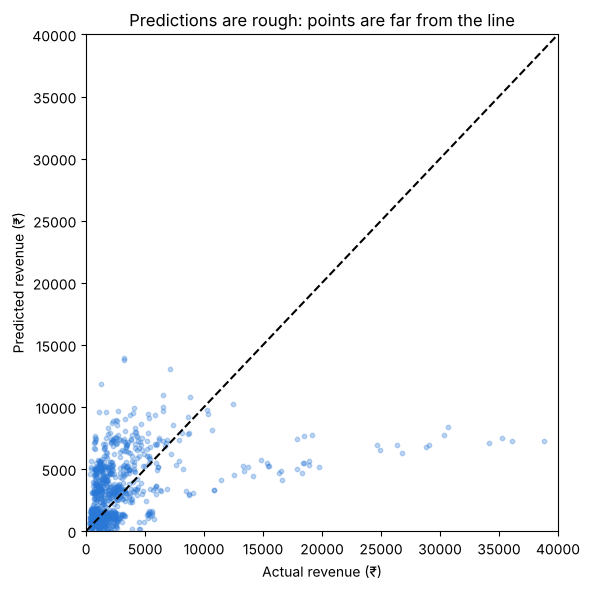

In [9]:
# Picture: predicted vs actual for test orders (perfect model = the dashed line)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.3, s=10, color="#2a78d6")
lim = [0, 40000]
plt.plot(lim, lim, "--", color="black")
plt.xlim(lim); plt.ylim(lim)
plt.xlabel("Actual revenue (₹)")
plt.ylabel("Predicted revenue (₹)")
plt.title("Predictions are rough: points are far from the line")
plt.tight_layout()
plt.show()